# Check GPU

In [ ]:

import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU available")


CUDA available: True
GPU: Tesla T4


# Install libraries

In [ ]:

%pip install -q -U ultralytics pandas pyyaml


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 4.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 83.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 128.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.


# Mount Google Drive and check the dataset

In [ ]:

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT = Path("/content/drive/MyDrive/Component03")
DATASET = PROJECT / "dataset"
YAML_PATH = DATASET / "data.yaml"

assert YAML_PATH.exists(), "data.yaml is missing!"

for split in ["train", "val", "test"]:
    images = list((DATASET / "images" / split).glob("*.jpg"))
    labels = list((DATASET / "labels" / split).glob("*.txt"))

    print(split, "images:", len(images),
          "labels:", len(labels))

print("Dataset ready!")


Mounted at /content/drive
train images: 156 labels: 156
val images: 34 labels: 34
test images: 33 labels: 33
Dataset ready!


# 5. Run a small training test first

In [ ]:

import shutil
import yaml
from pathlib import Path

LOCAL_DATASET = Path("/content/component03_dataset")

if LOCAL_DATASET.exists():
    shutil.rmtree(LOCAL_DATASET)

shutil.copytree(DATASET, LOCAL_DATASET)

local_config = {
    "path": str(LOCAL_DATASET),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {
        0: "car",
        1: "motorcycle",
        2: "bus",
        3: "truck"
    }
}

LOCAL_YAML = LOCAL_DATASET / "data.yaml"

with open(LOCAL_YAML, "w") as f:
    yaml.safe_dump(local_config, f, sort_keys=False)

print("Dataset copied successfully.")
print("Local configuration:", LOCAL_YAML)


Dataset copied successfully.
Local configuration: /content/component03_dataset/data.yaml


# – Test training for 3 epochs

In [ ]:

from ultralytics import YOLO
import torch

assert torch.cuda.is_available(), "Enable GPU in Colab."

pilot_model = YOLO("yolo11n.pt")

pilot_model.train(
    data=str(LOCAL_YAML),
    epochs=3,
    imgsz=640,
    batch=8,
    device=0,
    project="/content/component03_runs",
    name="pilot_yolo11n",
    seed=42,
    workers=2,
    plots=True
)

print("Pilot training completed!")


Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/component03_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=pilot_yolo11n, nbs=64, nms=None, opset=None, optimiz

In [ ]:
from pathlib import Path

pilot_weights = Path(
    "/content/component03_runs/pilot_yolo11n/weights/best.pt"
)

print("Weights saved:", pilot_weights.exists())

Weights saved: True


In [ ]:
from pathlib import Path

pilot_weights = Path(
    "/content/component03_runs/pilot_yolo11n/weights/best.pt"
)

print("Pilot model saved:", pilot_weights.exists())

Pilot model saved: True


# 6. Train the five independent models

In [ ]:
#Define the training experiments

from pathlib import Path

MODELS = {
    "yolo11n": "yolo11n.pt",
    "yolo11s": "yolo11s.pt",
    "yolo11m": "yolo11m.pt",
    "yolov8n": "yolov8n.pt",
    "yolo26n": "yolo26n.pt"
}

RUNS_DIR = Path("/content/component03_runs")
DRIVE_RUNS = PROJECT / "training_results"

DRIVE_RUNS.mkdir(parents=True, exist_ok=True)

EPOCHS = 40
IMAGE_SIZE = 640
BATCH_SIZE = 8

print("Models selected:", list(MODELS))


Models selected: ['yolo11n', 'yolo11s', 'yolo11m', 'yolov8n', 'yolo26n']


In [12]:
#Train each network separately

import shutil
import gc
import torch
from pathlib import Path
from ultralytics import YOLO

for model_name, checkpoint in MODELS.items():
    saved_dir = DRIVE_RUNS / model_name
    saved_best = saved_dir / "weights" / "best.pt"

    # Skip completed experiments, useful after
    # a Colab session disconnects.
    if saved_best.exists():
        print(f"Already saved: {model_name}")
        continue

    print(f"\nStarting training: {model_name}")

    model = YOLO(checkpoint)

    model.train(
        data=str(LOCAL_YAML),
        epochs=EPOCHS,
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        device=0,
        seed=42,
        deterministic=True,
        workers=2,
        patience=40,
        optimizer="AdamW",
        lr0=0.001,
        mosaic=0.5,
        mixup=0.0,
        plots=True,
        save=True,
        project=str(RUNS_DIR),
        name=model_name,
        exist_ok=False
    )

    local_run = Path(model.trainer.save_dir)
    drive_run = saved_dir

    shutil.copytree(
        local_run,
        drive_run,
        dirs_exist_ok=True
    )

    print("Saved:", drive_run)

    del model
    gc.collect()
    torch.cuda.empty_cache()

print("\nAll available model runs completed.")


Already saved: yolo11n
Already saved: yolo11s
Already saved: yolo11m
Already saved: yolov8n
Already saved: yolo26n

All available model runs completed.


# 7. Compare all five trained models

After completing the five experiments, we will compare them using the validation dataset.

The main metrics are:
Metric	Meaning
**Precision**	How many predicted vehicle detections were correct
**Recall**	How many actual vehicles were successfully detected
**mAP@0.5**	Detection accuracy at IoU threshold 0.5
**mAP@0.5:0.95**	Detection quality across multiple IoU thresholds
**Inference speed**	Time taken to process an image

In [13]:
#Evaluate the models

import pandas as pd
from ultralytics import YOLO

comparison = []

for model_name in MODELS:
    weights = (
        DRIVE_RUNS / model_name /
        "weights" / "best.pt"
    )

    if not weights.exists():
        print("Missing weights:", model_name)
        continue

    print("Evaluating:", model_name)

    model = YOLO(str(weights))

    metrics = model.val(
        data=str(LOCAL_YAML),
        split="val",
        imgsz=IMAGE_SIZE,
        batch=4,
        device=0,
        plots=False,
        verbose=False
    )

    comparison.append({
        "Model": model_name,
        "Precision": round(metrics.box.mp, 4),
        "Recall": round(metrics.box.mr, 4),
        "mAP50": round(metrics.box.map50, 4),
        "mAP50-95": round(metrics.box.map, 4),
        "Inference_ms": round(metrics.speed["inference"], 2)
    })

df_results = pd.DataFrame(comparison)

if df_results.empty:
    raise RuntimeError("No trained models were found.")

df_results = df_results.sort_values(
    "mAP50-95", ascending=False
)

display(df_results)

df_results.to_csv(
    PROJECT / "five_model_comparison.csv",
    index=False
)


Evaluating: yolo11n
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2742.8±1071.9 MB/s, size: 196.5 KB)
val: Scanning /content/component03_dataset/labels/val.cache... 34 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 34/34 9.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 10.3it/s 0.9s
                   all         34        202      0.468      0.445      0.421      0.255
Speed: 0.7ms preprocess, 13.8ms inference, 0.0ms loss, 1.2ms postprocess per image
Evaluating: yolo11s
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2684.5±1251.8 MB/s, size: 300.9 KB)
val: Scanning /co

,Model,Precision,Recall,mAP50,mAP50-95,Inference_ms
4,yolo26n,0.7422,0.3888,0.5456,0.3456,6.66
1,yolo11s,0.5711,0.4656,0.5420,0.3367,13.24
2,yolo11m,0.6106,0.4544,0.5205,0.3192,21.39
3,yolov8n,0.7751,0.3620,0.5170,0.3151,6.17
0,yolo11n,0.4682,0.4447,0.4211,0.2547,13.80


This will produce your actual model comparison table.

The inference measurements are useful for initial comparison, but for final research reporting, benchmark all models on identical hardware with warm-up runs and the same inference settings.

# 8. Visualize the comparison

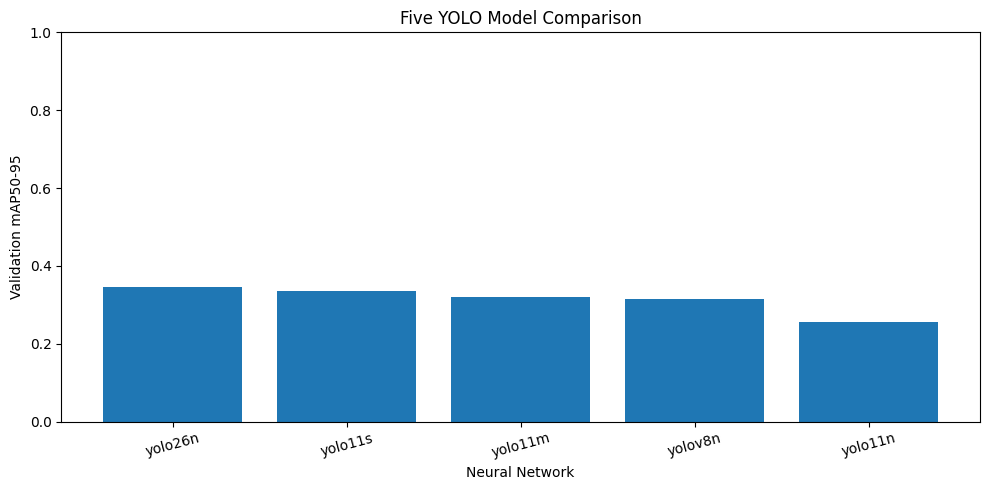

In [14]:
#Plot model performance

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    df_results["Model"],
    df_results["mAP50-95"]
)

plt.xlabel("Neural Network")
plt.ylabel("Validation mAP50-95")
plt.title("Five YOLO Model Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


After comparing the validation results, select the best detector using your chosen accuracy-versus-speed criteria.

You should then evaluate the selected model on the untouched test dataset:

In [15]:
best_name = df_results.iloc[0]["Model"]

best_weights = (
    DRIVE_RUNS / best_name /
    "weights" / "best.pt"
)

best_model = YOLO(str(best_weights))

test_metrics = best_model.val(
    data=str(LOCAL_YAML),
    split="test",
    imgsz=IMAGE_SIZE,
    device=0
)

print("Selected model:", best_name)
print("Test mAP50:", test_metrics.box.map50)
print("Test mAP50-95:", test_metrics.box.map)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 78.1±24.1 MB/s, size: 535.4 KB)
val: Scanning /content/component03_dataset/labels/test... 33 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 33/33 347.4it/s 0.1s
val: New cache created: /content/component03_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.8it/s 1.6s
                   all         33        232      0.344      0.262      0.245      0.113
                   car         33        184      0.703      0.424      0.436      0.255
            motorcycle         10         11      0.334      0.273      0.285     0.0712
                   bus          3          3          0          0          0          0
                 truck         16         34      0.338      0.35

The example selects the highest validation mAP50-95. For your actual Component 03, we will also evaluate how well each detector supports vehicle tracking, particularly under occlusion.

# Save the best models permanently

In [16]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/Component03")

for name in ["yolo26n", "yolo11s"]:
    weights = (
        PROJECT / "training_results" /
        name / "weights" / "best.pt"
    )

    print(name, ":", weights.exists())

yolo26n : True
yolo11s : True
